# Attaquer son propre détecteur d'intrusion : évasion adverse et durcissement

Projet 2 du module « Machine Learning pour la cyber-sécurité » (Tek-up), réalisé **seul** : l'étudiant joue successivement le rôle du défenseur (construction et durcissement du détecteur) et de l'attaquant (évasion).

Ce notebook est le rapport. Il est exécutable de haut en bas et **ne lit que des agrégats déjà enregistrés** dans `results/final/` et des documents de `docs/` : aucune donnée brute, aucun réentraînement. Les chiffres viennent de `python -m src.evaluation.final_evaluation --segment test`, exécuté une seule fois.

Étiquettes utilisées : **Observé** (mesuré), **Hypothèse**, **Planifié**, **Post hoc** (décidé après avoir vu un résultat).

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results" / "final"
DOCS = ROOT / "docs"
SEGMENT = "test"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def load(name):
    return pd.read_csv(RESULTS / f"{SEGMENT}_{name}.csv")


def show_doc(name):
    display(Markdown((DOCS / name).read_text(encoding="utf-8")))


print(sorted(p.name for p in RESULTS.glob(f"{SEGMENT}_*")))

['test_benign_perturbed.csv', 'test_clean.csv', 'test_console.txt', 'test_evasion.csv', 'test_evasion_comparison.csv', 'test_per_class.csv', 'test_per_family_clean.csv', 'test_pr_curve.csv', 'test_pr_curves.png', 'test_recall_common_family.csv', 'test_recall_common_pooled.csv', 'test_recall_vs_amplitude.png', 'test_validation_check.csv']


## 1. Problématique

Un détecteur d'intrusion par apprentissage automatique classe des flux réseau en « normal » ou « attaque ». Un attaquant peut modifier légèrement son trafic pour être classé « normal » : c'est une **attaque d'évasion**. Questions étudiées :

1. Les détecteurs retenus (régression logistique, forêt aléatoire, XGBoost) sont-ils évadables par un attaquant réaliste ?
2. Un **entraînement adverse** les rend-il plus résistants, et à quel coût sur la performance normale ?
3. Que vaut ce résultat face à ses limites (attaquant connu, modèle de menace restreint) ?

Un résultat modeste mais honnêtement évalué vaut mieux qu'un score élevé obtenu par une évaluation biaisée.

## 2. Données

- **CIC-IDS2017 « improved »** (CNS2022, Engelen et al.), version corrigée du jeu CIC-IDS2017 : cinq CSV journaliers (lundi à vendredi), flux réseau décrits par des statistiques (durée, paquets, octets, temps inter-arrivées…). Données publiques, aucune attaque contre un système réel.
- Archive officielle `CICIDS2017_improved.zip` (343 549 013 octets), non versionnée ; procédure d'obtention dans le README.
- Cible binaire : `BENIGN` et les variantes « Attempted » (tentatives sans effet) valent 0, les attaques effectives valent 1.

L'audit du jeu (labels, valeurs manquantes ou infinies, doublons) est dans `docs/dataset_audit_report.md`.

## 3. Préparation des données

- 80 variables en entrée ; métadonnées, adresses IP, ports, horodatage et `Header Length` exclus (variables identifiantes qui permettraient de « tricher »).
- Toutes les opérations apprises (imputation, normalisation pour la régression logistique) sont **ajustées sur le train seulement** (`src/data/preprocessing.py`, 30 tests `unittest`).
- Détails : `docs/preprocessing_protocol.md` et `docs/preprocessing_report.md`.

## 4. Méthodologie et découpage

**Premier protocole (par jour)** : lundi à mercredi pour le train, jeudi pour la validation, vendredi pour le test. Train et validation n'ont **aucune famille d'attaque en commun** : les modèles échouent presque totalement sur le jeudi. Ce résultat est gardé comme étude du décalage de distribution (`docs/temporal_baselines_report.md`).

**Protocole retenu (par strate), post hoc** : lundi à mercredi seulement ; chaque couple (jour, label) est trié par temps et coupé à 60 / 20 / 20 avec un intervalle d'exclusion de 1 % autour de chaque coupure (`src/data/temporal_split.py`). Train 702 310 lignes, validation 214 261, test 226 157. Ce choix a été fait **après** avoir vu les résultats du jeudi : le résultat principal est donc une **borne optimiste** (mêmes familles d'attaque en train et en test).

**Discipline d'évaluation** : réglage et développement sur la validation uniquement ; spécifications commitées **avant** exécution (`docs/hardening_specification.md`, `docs/final_evaluation_specification.md`) ; le segment test est lu **une seule fois**, par un script qui vérifie d'abord que les six modèles reconstruits reproduisent exactement les FP/FN de la validation.

In [2]:
check = load("validation_check")
display(check)
print("Reproduction des modèles :", "OK" if check["match"].all() else "ÉCART")

,detector,state,FP,FN,expected,match,fit_s
0,LogReg,original,509,274,"(509, 274)",True,6.6
1,LogReg,hardened,444,227,"(444, 227)",True,10.5
2,RandomForest,original,11,40,"(11, 40)",True,42.1
3,RandomForest,hardened,12,26,"(12, 26)",True,45.4
4,XGBoost,original,7,36,"(7, 36)",True,6.1
5,XGBoost,hardened,5,10,"(5, 10)",True,4.9


Reproduction des modèles : OK


## 5. Modèle de menace

Résumé (détail dans les documents ci-dessous) : attaquant **boîte noire à score** (il interroge le détecteur et lit sa probabilité), **1 000 requêtes au plus par flux**, qui ne perturbe que des attaques **déjà détectées** (sinon l'évasion serait gratuite). Il ne contrôle que le côté `Fwd` du flux (**hypothèse** non prouvée : l'attaquant est le client qui initie la connexion) : remplissage des paquets (facteur `s`) et délai (facteur `t`), tous deux dans `[1, 1 + A]`. Les variables dérivées sont recalculées par des formules **vérifiées sur les données** ; une règle de réalisme rejette tout candidat hors des bornes du train, qui casse un ordre vérifié ou dépasse 1 500 octets par paquet.

In [3]:
show_doc("threat_model.md")

# Threat Model and Evasion Protocol — Individual Work

**Statut : modèle initial ; les variables autorisées dépendront de l'audit de contrôlabilité.**

## Objectif de l'attaquant

Faire classer comme normal un flux malveillant qui était initialement correctement classé comme attaque par le détecteur de référence. Les flux malveillants déjà mal classés ne seront pas comptés comme des évasions.

## Connaissance et accès

Le scénario initial est une attaque boîte noire à score :

- l'attaquant peut interroger le détecteur et obtenir un score ou une probabilité ;
- il ne connaît ni les paramètres, ni les variables d'entraînement, ni les données d'entraînement ;
- il travaille hors ligne sur des copies des échantillons ;
- le budget est limité à **1 000 requêtes par échantillon attaqué**.

Si une interface de score n'est pas justifiée par le déploiement simulé, un scénario à sortie de classe devra être évalué séparément plutôt que supposé équivalent.

## Capacités et restrictions

L'attaquant peut modifier uniquement les variables marquées autorisées dans `feature_controllability.md`. Chaque candidat doit respecter :

- bornes observées sur l'entraînement et contraintes de type ;
- dépendances entre durée, paquets, octets, débits et moyennes ;
- cohérence avec le protocole, l'état et le service ;
- budget de requêtes et amplitude fixée avant le test.

Les identifiants, timestamps, adresses, variables de groupe et champs dont la modification change l'identité de l'attaque sont interdits, sauf justification contraire documentée. Les exemples impossibles sont rejetés et comptés.

## Méthode prévue

La première méthode sera une recherche aléatoire de perturbations bornées. Elle sera développée et réglée sur la validation uniquement. Le modèle original, les amplitudes, le masque de variables et le budget seront gelés avant l'évaluation finale. Les échantillons originaux resteront inchangés ; les candidats modifiés seront sauvegardés séparément avec leur `sample_id`.

Cette méthode produit des attaques dans l'espace des caractéristiques. Elle ne prouve pas qu'un trafic réseau réel peut être reconstruit sans implémentation et vérification au niveau des paquets.

## Mesures

- taux d'évasion parmi les attaques initialement correctement détectées ;
- rappel avant et après attaque ;
- chute du rappel selon l'amplitude ;
- nombre médian et maximal de requêtes ;
- taux de rejet pour borne, type ou incohérence ;
- résultats par famille d'attaque lorsque les effectifs le permettent.

Les intervalles ou dénominateurs seront rapportés lorsque le nombre de cas est faible.

## Durcissement

Le premier défenseur candidat est le réentraînement avec des exemples adverses produits à partir de l'entraînement. La validation sert au choix de la configuration ; le test n'est jamais utilisé pour générer ces exemples. Le modèle durci sera évalué sur trafic normal, puis soumis à un rejeu de l'attaque sous protocole fixé.

## Limites à déclarer

Une perturbation CSV n'est pas automatiquement une modification de trafic réalisable. Les agrégats peuvent dépendre de plusieurs flux, le score peut ne pas être disponible en situation réelle et l'attaque peut être spécifique au modèle. Ces limites seront conservées dans le rapport final.

## Organisation du travail

Le modèle de menace, l'attaque, le durcissement et leur évaluation sont réalisés séquentiellement par l'auteur du projet. Les paramètres sont gelés avant le test final et les résultats sont conservés avec leur configuration exacte.


## Précisions issues de la Phase 4 (décisions provisoires, à confirmer)

- **Détecteur cible provisoire** : XGBoost, configuration retenue par la règle déclarée (profondeur 3, 100 arbres) ; forêt et régression
  logistique réservées à l'extension « transfert ».
- **Seuil de décision** : 0,5, figé. Évasion réussie = score < 0,5 pour un flux de cible 1 initialement détecté (score >= 0,5).
- **Dénominateur du taux d'évasion** : flux de cible 1 détectés à 0,5 par le modèle cible. Exclus : les flux `Attempted` (cible 0) et les
  attaques déjà non détectées (36 faux négatifs en validation pour la configuration retenue).
- **Familles attaquées** : à justifier dans le rapport (DoS volumétrique, DoS lent, force brute) ; non décidé.
- **Référence « sans effort »** : le test « une famille retirée » montre qu'un changement de famille échappe déjà au détecteur dans
  plusieurs cas (rappel 0 pour les deux Patator, partiel pour les DoS) ; point de comparaison pour l'attaque contrainte.
- **Hypothèse à valider** : attaquant = client initiateur (Fwd = attaquant, Bwd = serveur) ; les ports sont cohérents avec elle sans la prouver.
- **Dépendance du modèle** : `Bwd Packet Length Std` pèse 0,6068 du gain XGBoost (configuration profondeur 6, 200 arbres de la Phase 4.4 ;
  à recalculer pour la configuration retenue). Variable côté serveur dans l'hypothèse ci-dessus : si elle tient, la surface d'attaque est
  réduite, et un faible taux d'évasion serait un résultat du modèle de menace, pas un échec de l'attaque.

## Profil du détecteur cible sur la validation (observé)

**Observé** (`src/models/selected_detector_profile.py`). XGBoost max_depth 3, n_estimators 100, learning_rate 0,1, graine 42, stratégie `exclude`,
seuil 0,5, ajusté sur le segment train. Segment test, jeudi et vendredi non chargés.

- Attaques de validation : 32 144 ; détectées à 0,5 : 32 108 ; manquées : 36 (25 GoldenEye, 7 Hulk, 2 Slowhttptest, 2 Heartbleed).
- Dénominateur par famille : Hulk 28 517 ; GoldenEye 1 337 ; Slowloris 695 ; FTP-Patator 715 ; SSH-Patator 533 ; Slowhttptest 311 ; Heartbleed 0.
- Scores des attaques détectées (quantiles 5 % / 50 % / 95 %) : Hulk 0,9995 / 0,9999 / 0,9999 ; GoldenEye 0,9603 / 0,9999 / 0,9999 ;
  Slowhttptest 0,7587 / 0,9972 / 0,9972 ; Slowloris 0,9842 / 0,9970 / 0,9972 ; FTP-Patator 0,9966 / 0,9970 / 0,9970 ; SSH-Patator 0,9638 / 0,9944 / 0,9948.
- Importances (gain) : `Bwd Packet Length Std` 0,5572 ; `Packet Length Mean` 0,0550 ; `Packet Length Std` 0,0431 ; `Bwd IAT Max` 0,0415 ;
  `Fwd IAT Max` 0,0331 ; `Fwd Seg Size Min` 0,0315 ; `Total TCP Flow Time` 0,0113. Regroupement par nom : bwd 0,7211 ; fwd 0,0881 ; other 0,1908.
- La valeur 0,6068 citée plus haut concerne la configuration de la Phase 4.4 (profondeur 6, 200 arbres) ; pour la configuration retenue : 0,5572.

**Hypothèses, non démontrées** : détections à forte confiance ; scores constants par morceaux (arbres peu profonds) ; dépendance forte au côté serveur,
qui réduirait la surface d'attaque d'un attaquant limité à Fwd ; `Bwd Packet Length Std` pourrait refléter une signature du serveur victime ;
`Fwd Seg Size Min` à reclasser (taille d'en-tête possible).

In [4]:
show_doc("feature_controllability.md")

# Feature Controllability Audit — Individual Work

**Statut : grille préparatoire ; les colonnes exactes seront confirmées après inspection des fichiers CIC-IDS2017.**

## Objectif

Déterminer ce qu'un attaquant peut modifier dans un flux sans supposer qu'une valeur numérique est librement manipulable. Cette analyse définit les contraintes de l'attaque, mais ne décide pas seule quelles variables le détecteur peut utiliser.

## Distinction obligatoire

Deux décisions indépendantes doivent être documentées :

1. **Inclusion dans le détecteur** : la variable est-elle observable, utile et exempte de fuite ou d'artefact ?
2. **Contrôlabilité par l'attaquant** : la variable peut-elle être modifiée sans coût, avec coût, ou seulement en changeant/détruisant l'attaque ?

Ainsi, une variable non modifiable n'est pas automatiquement supprimée du détecteur. Elle est seulement placée dans le masque des variables interdites pour l'attaque.

## Catégories finales

| Catégorie | Signification |
|---|---|
| Librement modifiable | Modification plausible sans changer l'objectif de l'attaque, sous réserve de cohérence |
| Modifiable avec un coût | Modification possible mais nécessitant du temps, des paquets, des ressources ou un compromis opérationnel |
| Non modifiable sans détruire ou changer l'attaque | Variable observée mais non contrôlable dans le scénario retenu |

Une quatrième valeur **à vérifier** sera utilisée temporairement pendant l'audit ; elle ne pourra pas rester dans le modèle de menace final.

## Groupes à examiner

| Groupe | Inclusion dans le détecteur | Contrôlabilité initiale à vérifier |
|---|---|---|
| Flow ID, IP, ports, timestamps | Décision séparée selon risque d'artefact | Souvent non modifiable ou sémantiquement déterminant |
| Durée, paquets et octets | Candidats possibles | Généralement modifiables avec coût et dépendances |
| Débits, moyennes et intervalles | Candidats possibles | Variables dérivées ; ne pas modifier indépendamment |
| Protocoles, états et flags | Candidats possibles | Souvent liés au service ou à l'attaque |
| TTL, fenêtres et compteurs | Candidats possibles | Coût, dépendances ou impossibilité selon le scénario |
| Agrégats de connexions | À auditer pour fuite | Dépendent d'autres flux et de l'horizon d'observation |

Cette table est une hypothèse de travail, pas une autorisation de perturbation.

## Fiche par variable

Pour chaque colonne réelle, documenter : nom, définition, type, source, variable dérivée ou non, relations connues, observabilité, inclusion dans le détecteur, catégorie de contrôlabilité, coût, borne, règle de cohérence et justification.

## Limite de représentation

L'attaque prévue modifie des vecteurs de caractéristiques. Elle ne reconstruit pas les paquets ni ne recalcule un flux à partir d'une capture. Les résultats seront donc décrits comme des attaques dans l'espace des caractéristiques. Toute affirmation de réalisme réseau nécessitera une reconstruction et une vérification indépendantes.

## Critères d'acceptation

- toutes les colonnes du fichier retenu sont classées ;
- inclusion modèle et contrôlabilité sont séparées ;
- les relations entre compteurs, débits et moyennes sont testées ;
- le masque d'attaque est figé avant l'évaluation finale ;
- les échantillons incohérents sont rejetés et comptés.

## Organisation du travail

Cette analyse est réalisée individuellement après l'inspection du schéma réel et avant l'implémentation de l'attaque. Elle constitue une étape obligatoire du modèle de menace, pas une contribution séparée ou fictive.


## Inventaire et relations mesurés (segment train, lundi-mercredi)

**Observé** (`src/data/feature_inventory.py`, `src/data/feature_relations.py`). Validation, test, jeudi et vendredi non chargés.

- 80 variables en entrée (79 numériques + `Protocol`, stratégie `exclude`).
- Constantes à 0 : `Fwd URG Flags`, `Bwd URG Flags`, `URG Flag Count` ; `Subflow Bwd Packets` quasi constante.
- `ICMP Type` et `ICMP Code` sont des identifiants numériques (minimum -1), pas des mesures continues.
- 16 relations sur 17 tiennent à 0,1 % près sur toutes les lignes éligibles (erreur médiane nulle) : totaux = moyenne x nombre de paquets,
  débits = comptes / durée x 1e6 (durées en microsecondes), `Down/Up Ratio`, `Packet Length Mean` et `Max`, `Variance` = `Std`^2,
  et quatre redondances exactes (`Fwd Segment Size Avg`, `Bwd Segment Size Avg`, `Average Packet Size`, `Packet Length Variance`).
- `Total TCP Flow Time <= Flow Duration` ne tient que dans 95,63 % des lignes (environ 30 700 violations), cause non expliquée.
- Un flux de durée nulle et 18 flux sans paquet Fwd (déduits des effectifs éligibles).
- Un seul port de destination par famille d'attaque (DoS : 80 ; FTP-Patator : 21 ; SSH-Patator : 22 ; Heartbleed : 444).

**Classification provisoire** (hypothèse de travail : l'attaquant est le client qui initie le flux ; Fwd = attaquant, Bwd = serveur).

| Groupe | Variables | Catégorie provisoire | Réserve |
|---|---|---|---|
| Tailles Fwd | `Fwd Packet Length Max/Min/Mean/Std`, `Fwd Segment Size Avg`, `Fwd Seg Size Min` | avec un coût | rembourrage coûteux en bande passante ; limites du protocole applicatif |
| Volume Fwd | `Total Fwd Packet`, `Total Length of Fwd Packet` | avec un coût | le volume fait souvent partie de l'attaque |
| Rythme Fwd | `Fwd IAT Total/Mean/Std/Max/Min` | avec un coût | espacer les paquets réduit le débit d'attaque |
| Fenêtre initiale Fwd | `FWD Init Win Bytes` | à vérifier | |
| Côté serveur | variables `Bwd` | non modifiable directement | produites par la réponse du serveur |
| Protocole et flags | `Protocol`, `ICMP Type/Code`, compteurs de flags, `Fwd PSH/RST Flags` | non modifiable (à vérifier flag par flag) | définissent la nature de l'attaque |
| Dérivées vérifiées | débits, `Down/Up Ratio`, `Packet Length Mean/Max`, copies exactes | recalculées, jamais perturbées directement | formules mesurées |
| Dérivées non vérifiées | `Packet Length Std/Variance`, IAT stats, `Active/Idle`, `Bulk`, `Subflow*`, `Total TCP Flow Time` | à vérifier | pas de formule validée |
| Constantes | trois variables URG, `Subflow Bwd Packets` | sans objet | aucune information |

**Limites** : la classification est un jugement à valider, pas une mesure ; l'inclusion dans le détecteur reste une décision séparée.

## Relations mesurées, deuxième lot (segment train, lundi-mercredi)

**Observé** (`src/data/feature_relations_more.py`). Validation, test, jeudi et vendredi non chargés.

- `Packet Length Variance` = variance poolée avec correction n-1 (moyennes, écarts-types et comptes Fwd/Bwd) : tient sur 100 % des lignes ;
  la formule avec n : 8,07 %.
- `Packet Length Min` = minimum sur les directions non vides : 100 % ; `Flow IAT Mean` x (paquets-1) = `Flow Duration` : 100 % ;
  `Fwd IAT Mean` x (Fwd-1) = `Fwd IAT Total` et idem Bwd : 100 % ; `PSH`/`RST Flag Count` = somme Fwd + Bwd : 100 % ;
  `Flow IAT Min` <= Mean <= Max <= `Flow Duration` : 100 %.
- `Subflow Fwd/Bwd Bytes` ne sont pas des totaux : relation vraie sur 3,82 % / 5,50 % des lignes seulement, soit la part de zéros
  de `Total Length of Fwd/Bwd Packet` (déduction). Signification non établie.
- `Total TCP Flow Time` > `Flow Duration` : 30 658 lignes (4,37 %), toutes TCP (9,09 % des flux TCP, 0 en UDP ou autres protocoles),
  rapport médian 35,4 ; par famille : BENIGN 3,93 %, DoS Hulk 6,11 %, DoS Slowhttptest 29,02 %, DoS Slowloris 42,25 %, Patator 0 %.
  Les familles `Attempted` à 85-96 % ont 7 à 48 flux.

**Hypothèse, non testée** : `Flow Duration` plafonne à 1,2e8 us (120 s) ; `Total TCP Flow Time` monte à environ 18 900 s. Elle pourrait mesurer
la connexion entière au-delà de l'enregistrement de flux, donc dépendre d'autres flux. À tester en ablation.

**Mise à jour de la classification**
- Recalculables (formules vérifiées) : totaux, débits, `Down/Up Ratio`, `Packet Length Mean/Max/Min/Std/Variance`, copies exactes,
  `Flow IAT Mean`, `Fwd/Bwd IAT Mean`, compteurs PSH et RST.
- Bornes d'ordre seulement : `Flow IAT Min/Max`, `Fwd/Bwd IAT Min/Max`.
- Non recalculables : `IAT Std`, `Active*`, `Idle*`, `Bulk*`, `Subflow*`, `Total TCP Flow Time` (non modifiable).

**Limite** : les variables non recalculables seraient gardées à leur valeur d'origine lors d'une perturbation ; le réalisme est alors
seulement partiel, ce qui doit figurer dans le rapport final.

## 6. Modèles

Configurations retenues par une règle de réglage **déclarée avant exécution** (graine 42, seuil 0,5, `docs/tuning_report.md`) :

| Modèle | Configuration |
|---|---|
| Régression logistique (baseline) | `C = 0,1`, variables normalisées |
| Forêt aléatoire | 100 arbres, `min_samples_leaf = 20` |
| XGBoost | profondeur 3, 100 arbres |

Défaut reconnu : la tolérance de 0,001 de la règle de sélection est plus grande que l'écart de PR-AUC entre configurations de la forêt et de XGBoost ; elle a donc choisi par simplicité.

## 7. Attaque d'évasion

- **Recherche aléatoire** : pour chaque flux, des couples `(s, t)` tirés uniformément dans `[1, 1 + A]²`, candidats irréalistes rejetés sans requête, au plus 1 000 requêtes ; amplitudes A = 0,1 ; 0,25 ; 0,5 ; 1 ; 2 (graine 1234).
- **Grille déterministe** 31 × 31 sur `[1, 3]²` (A = 2, 961 requêtes au plus) pour vérifier que la recherche aléatoire ne rate pas des évasions.
- **Population d'évasion** : au plus 300 flux détectés par famille et par modèle (graine 42). **Population commune** : au plus 300 attaques par famille, identiques pour les six modèles ; un flux manqué au départ ou évadé compte comme manqué (rappel sous attaque).

Résultat de développement (validation, `docs/multi_target_attack_report.md`) : XGBoost quasi insensible (2 évasions sur 1 800 flux), car l'essentiel de son importance porte sur des variables `Bwd` que l'attaquant ne contrôle pas. **Post hoc** : la régression logistique et la forêt sont attaquables (SSH-Patator surtout).

## 8. Défense : entraînement adverse

Spécification commitée avant le code (`docs/hardening_specification.md`) : pour chaque flux d'attaque du **train**, une copie perturbée réalisable (20 tirages dans `[1, 2]²`, premier candidat réalisable, A_train = 1), ajoutée à l'entraînement avec l'étiquette 1 ; réentraînement depuis zéro, mêmes hyperparamètres. Sur le train : 105 045 copies ajoutées, 319 flux sans candidat réalisable, part d'attaques de 15,00 % à 26,06 %. L'évaluation utilise une **autre graine**, une autre méthode (grille) et une **force supérieure** (A = 2 > A_train).

## 9. Résultats (segment test, exécution unique)

### 9.1 Performance propre

In [5]:
clean = load("clean")
display(clean.round(4))

,detector,state,precision,recall,F1,PR-AUC,FP,FN,TP,TN,inference_s
0,LogReg,original,0.9918,0.9815,0.9867,0.9945,275,626,33300,191956,0.49
1,LogReg,hardened,0.9940,0.9833,0.9886,0.9950,201,567,33359,192030,0.43
2,RandomForest,original,0.9999,0.9848,0.9923,0.9999,3,516,33410,192228,0.61
3,RandomForest,hardened,0.9999,0.9854,0.9926,0.9997,3,497,33429,192228,0.61
4,XGBoost,original,0.9999,0.9915,0.9957,0.9999,4,287,33639,192227,0.36
5,XGBoost,hardened,0.9999,0.9921,0.9960,0.9999,4,267,33659,192227,0.47


In [6]:
display(load("per_class").round(4))

,detector,state,class,precision,recall,f1-score,support
0,LogReg,original,0,0.9967,0.9986,0.9977,192231.0
1,LogReg,original,1,0.9918,0.9815,0.9867,33926.0
2,LogReg,hardened,0,0.9971,0.9990,0.9980,192231.0
3,LogReg,hardened,1,0.9940,0.9833,0.9886,33926.0
4,RandomForest,original,0,0.9973,1.0000,0.9987,192231.0
5,RandomForest,original,1,0.9999,0.9848,0.9923,33926.0
6,RandomForest,hardened,0,0.9974,1.0000,0.9987,192231.0
7,RandomForest,hardened,1,0.9999,0.9854,0.9926,33926.0
8,XGBoost,original,0,0.9985,1.0000,0.9992,192231.0
9,XGBoost,original,1,0.9999,0.9915,0.9957,33926.0


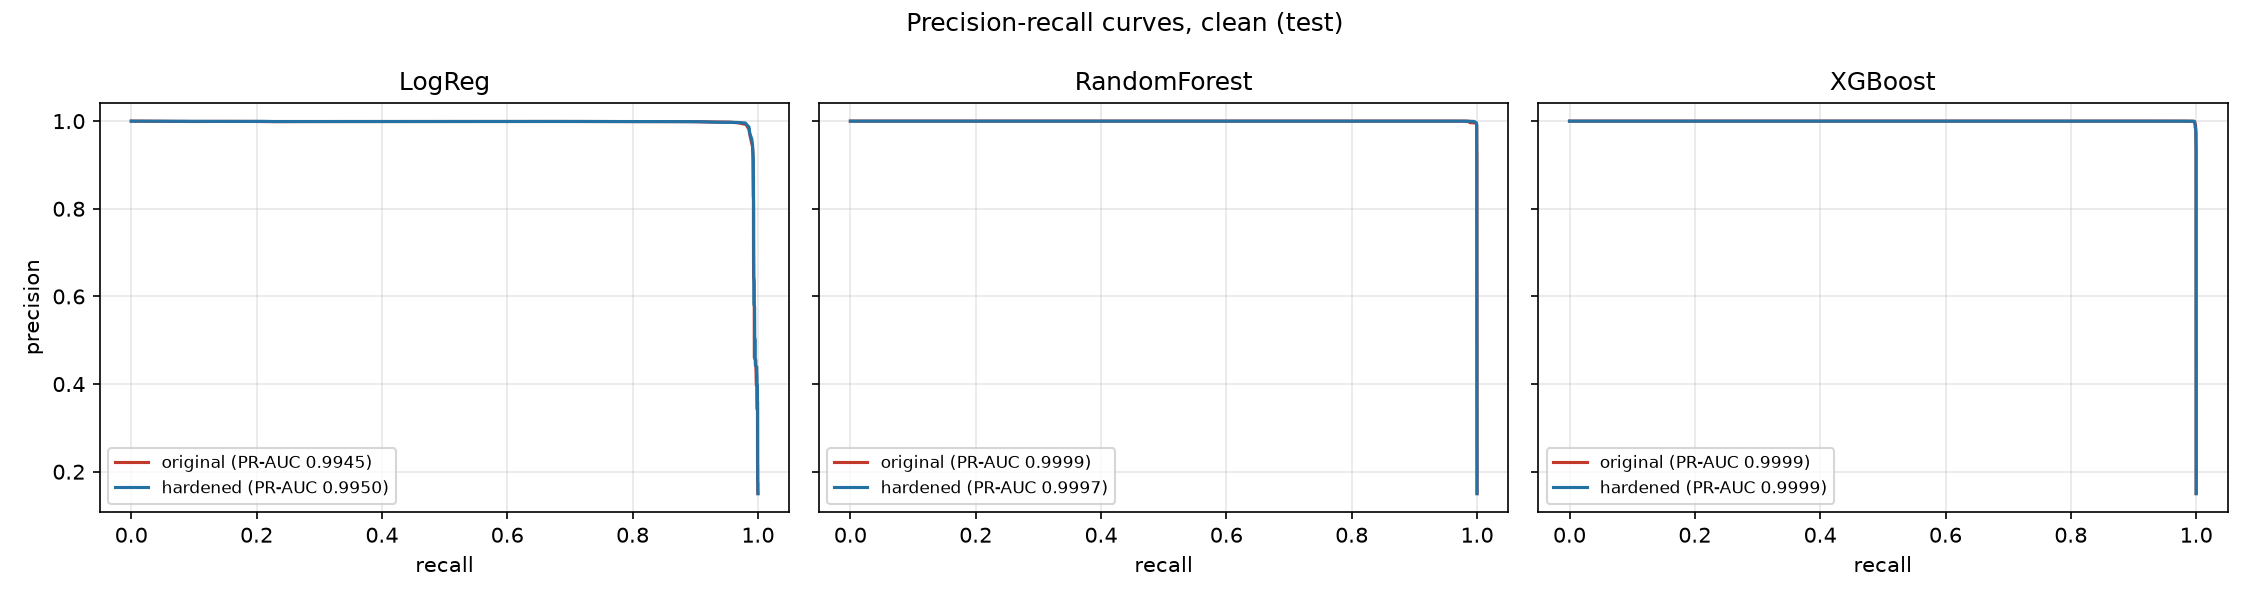

In [7]:
display(Image(filename=str(RESULTS / f"{SEGMENT}_pr_curves.png")))

In [8]:
fam = load("per_family_clean")
display(fam.pivot_table(index=["family", "n"], columns=["detector", "state"], values="recall").round(4))

detector                 LogReg          RandomForest           XGBoost         
state                  hardened original     hardened original hardened original
family           n                                                              
DoS GoldenEye    1437    0.9012   0.9040       1.0000   0.9986   1.0000   1.0000
DoS Hulk         30108   0.9990   0.9988       0.9998   0.9998   0.9999   0.9997
DoS Slowhttptest 330     0.3364   0.3333       0.5061   0.4576   0.8727   0.8303
DoS Slowloris    733     0.8213   0.7558       0.6139   0.6139   0.7503   0.7503
FTP-Patator      754     0.9947   0.9947       0.9867   0.9867   0.9947   0.9947
Heartbleed       2       1.0000   1.0000       0.0000   0.0000   0.0000   0.0000
SSH-Patator      562     0.9253   0.9110       0.9413   0.9413   0.9431   0.9413

### 9.2 Rappel sous attaque selon l'amplitude, avant et après durcissement

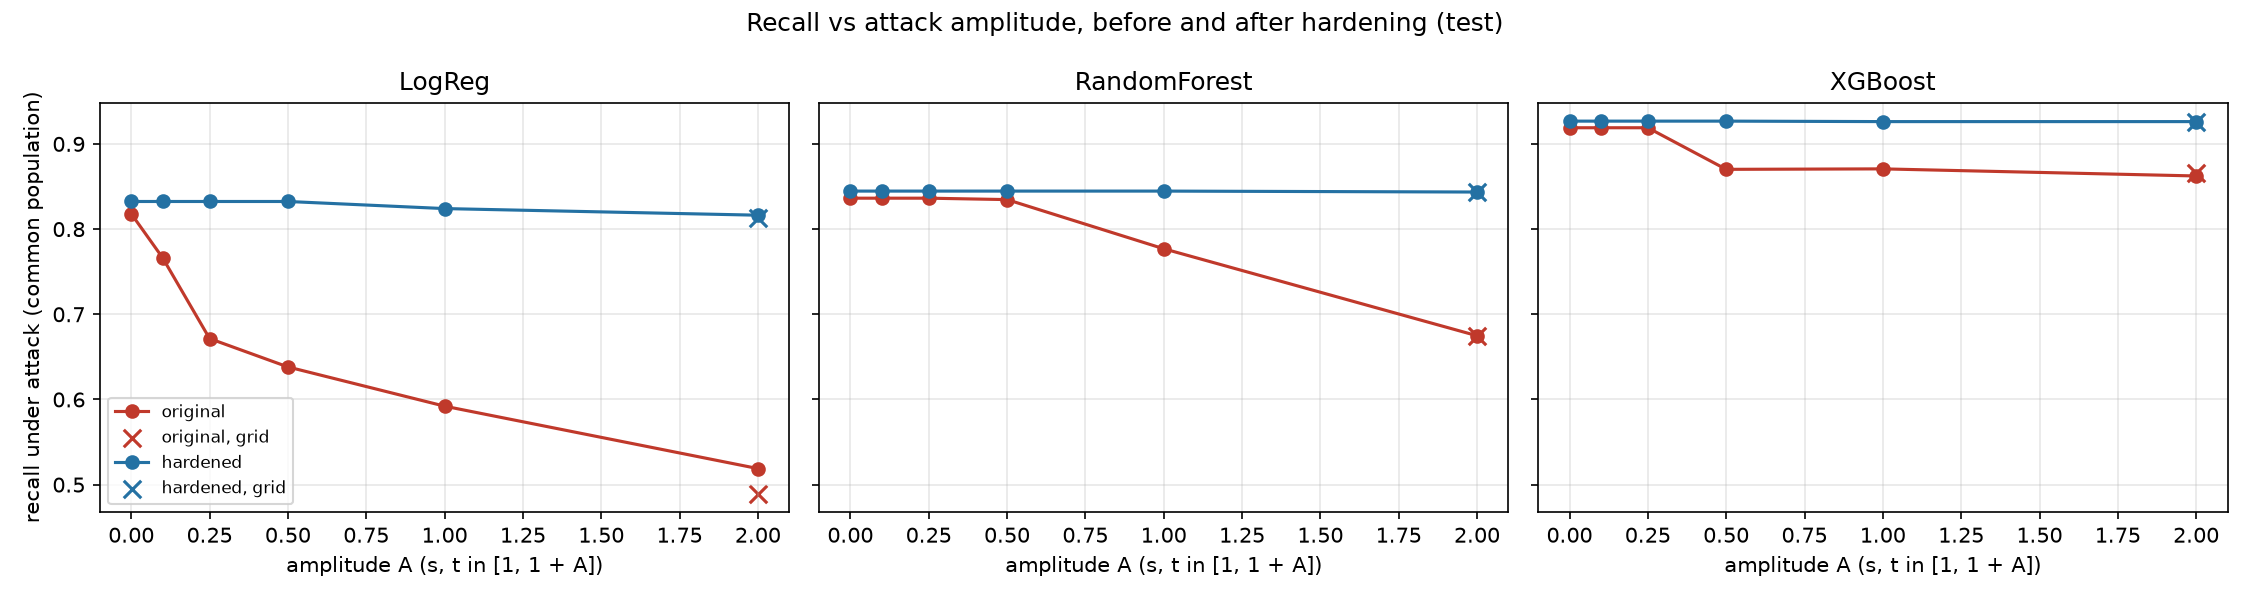

attack                 grid A=2.0    none  random A=0.1  random A=0.25  random A=0.5  random A=1.0  random A=2.0
detector     state                                                                                              
LogReg       hardened      0.8130  0.8324        0.8324         0.8324        0.8324        0.8241        0.8163
             original      0.4895  0.8180        0.7664         0.6715        0.6382        0.5921        0.5189
RandomForest hardened      0.8435  0.8446        0.8446         0.8446        0.8446        0.8446        0.8435
             original      0.6748  0.8363        0.8363         0.8363        0.8346        0.7769        0.6748
XGBoost      hardened      0.9262  0.9267        0.9267         0.9267        0.9267        0.9262        0.9262
             original      0.8657  0.9190        0.9190         0.9190        0.8701        0.8707        0.8624

In [9]:
display(Image(filename=str(RESULTS / f"{SEGMENT}_recall_vs_amplitude.png")))
pooled = load("recall_common_pooled")
display(pooled.pivot_table(index=["detector", "state"], columns="attack", values="recall").round(4))

### 9.3 Taux d'évasion et nombre de requêtes

In [10]:
evasion = load("evasion")
informative = evasion[evasion["evaded"] > 0]
cols = ["detector", "state", "family", "attack", "attacked", "evaded", "rate", "ci_low", "ci_high",
        "median_queries_evaders", "max_queries_evaders"]
display(informative[cols].round(4))
comparison = load("evasion_comparison")
print(comparison["verdict"].value_counts())

,detector,state,family,attack,attacked,evaded,rate,ci_low,ci_high,median_queries_evaders,max_queries_evaders
0,LogReg,original,DoS GoldenEye,random A=0.1,300,1,0.0033,0.0006,0.0186,11.0,11.0
1,LogReg,original,DoS GoldenEye,random A=0.25,300,2,0.0067,0.0018,0.0240,36.5,72.0
2,LogReg,original,DoS GoldenEye,random A=0.5,300,22,0.0733,0.0489,0.1085,8.5,157.0
3,LogReg,original,DoS GoldenEye,random A=1.0,300,78,0.2600,0.2136,0.3124,3.5,853.0
4,LogReg,original,DoS GoldenEye,random A=2.0,300,80,0.2667,0.2198,0.3194,2.0,22.0
...,...,...,...,...,...,...,...,...,...,...,...
169,XGBoost,original,DoS Slowhttptest,random A=1.0,274,97,0.3540,0.2998,0.4123,2.0,139.0
170,XGBoost,original,DoS Slowhttptest,random A=2.0,274,87,0.3175,0.2652,0.3748,4.0,37.0
175,XGBoost,original,DoS Slowloris,random A=2.0,300,28,0.0933,0.0654,0.1316,26.0,71.0
188,XGBoost,original,DoS Slowhttptest,grid A=2.0,274,83,0.3029,0.2515,0.3597,NaN,NaN


verdict
not separated    78
improved         36
Name: count, dtype: int64


### 9.4 Coût du durcissement sur des flux normaux perturbés

In [11]:
display(load("benign_perturbed").round(4))

,detector,state,A,feasible_share,flagged_before,flagged_after
0,LogReg,original,0.5,0.8901,0.0013,0.0026
1,LogReg,original,1.0,0.8712,0.0013,0.0049
2,LogReg,original,2.0,0.8394,0.0013,0.0052
3,LogReg,hardened,0.5,0.8901,0.0016,0.0075
4,LogReg,hardened,1.0,0.8712,0.0016,0.0178
5,LogReg,hardened,2.0,0.8394,0.0015,0.0252
6,RandomForest,original,0.5,0.8901,0.0000,0.0000
7,RandomForest,original,1.0,0.8712,0.0000,0.0000
8,RandomForest,original,2.0,0.8394,0.0000,0.0000
9,RandomForest,hardened,0.5,0.8901,0.0001,0.0001


### 9.5 Vendredi : étude du décalage (exécution unique, séparée)

Le vendredi (Portscan, DDoS, Botnet) contient des **familles absentes du train** : il mesure la généralisation hors distribution, pas la robustesse adverse. **Post hoc** : une première exécution s'est arrêtée sur un label inconnu (`Botnet - Attempted`, propre au vendredi) **avant tout calcul de score** ; il a été ajouté aux labels « Attempted » (valeur 0) par un commit séparé, puis l'évaluation a été relancée.

,detector,state,precision,recall,F1,PR-AUC,FP,FN,TP,TN,inference_s
0,LogReg,original,0.9909,0.4461,0.6153,0.9820,1042,141208,113738,291569,0.98
1,LogReg,hardened,0.9911,0.6937,0.8162,0.9817,1581,78086,176860,291030,1.52
2,RandomForest,original,1.0000,0.3725,0.5428,0.9915,3,159982,94964,292608,2.83
3,RandomForest,hardened,1.0000,0.3731,0.5434,0.9968,3,159835,95111,292608,1.50
4,XGBoost,original,0.9999,0.3201,0.4849,0.9554,6,173340,81606,292605,0.94
5,XGBoost,hardened,0.9999,0.2653,0.4193,0.9608,10,187307,67639,292601,1.13


detector          LogReg          RandomForest           XGBoost         
state           hardened original     hardened original hardened original
family   n                                                               
Botnet   736      0.0448   0.0000       0.0000   0.0000   0.0000   0.0000
DDoS     95144    0.9988   0.9985       0.9988   0.9972   0.7100   0.8568
Portscan 159066   0.5142   0.1178       0.0005   0.0005   0.0005   0.0005

attack                 grid A=2.0    none  random A=0.1  random A=0.25  random A=0.5  random A=1.0  random A=2.0
detector     state                                                                                              
LogReg       hardened      0.5256  0.5256        0.5256         0.5256        0.5256        0.5256        0.5256
             original      0.3844  0.3844        0.3844         0.3844        0.3844        0.3844        0.3844
RandomForest hardened      0.3333  0.3333        0.3333         0.3333        0.3333        0.3333        0.3333
             original      0.3333  0.3333        0.3333         0.3333        0.3333        0.3333        0.3333
XGBoost      hardened      0.0011  0.2344        0.2344         0.2344        0.2344        0.0011        0.0011
             original      0.0000  0.2889        0.2889         0.2300        0.2300        0.0000        0.0000

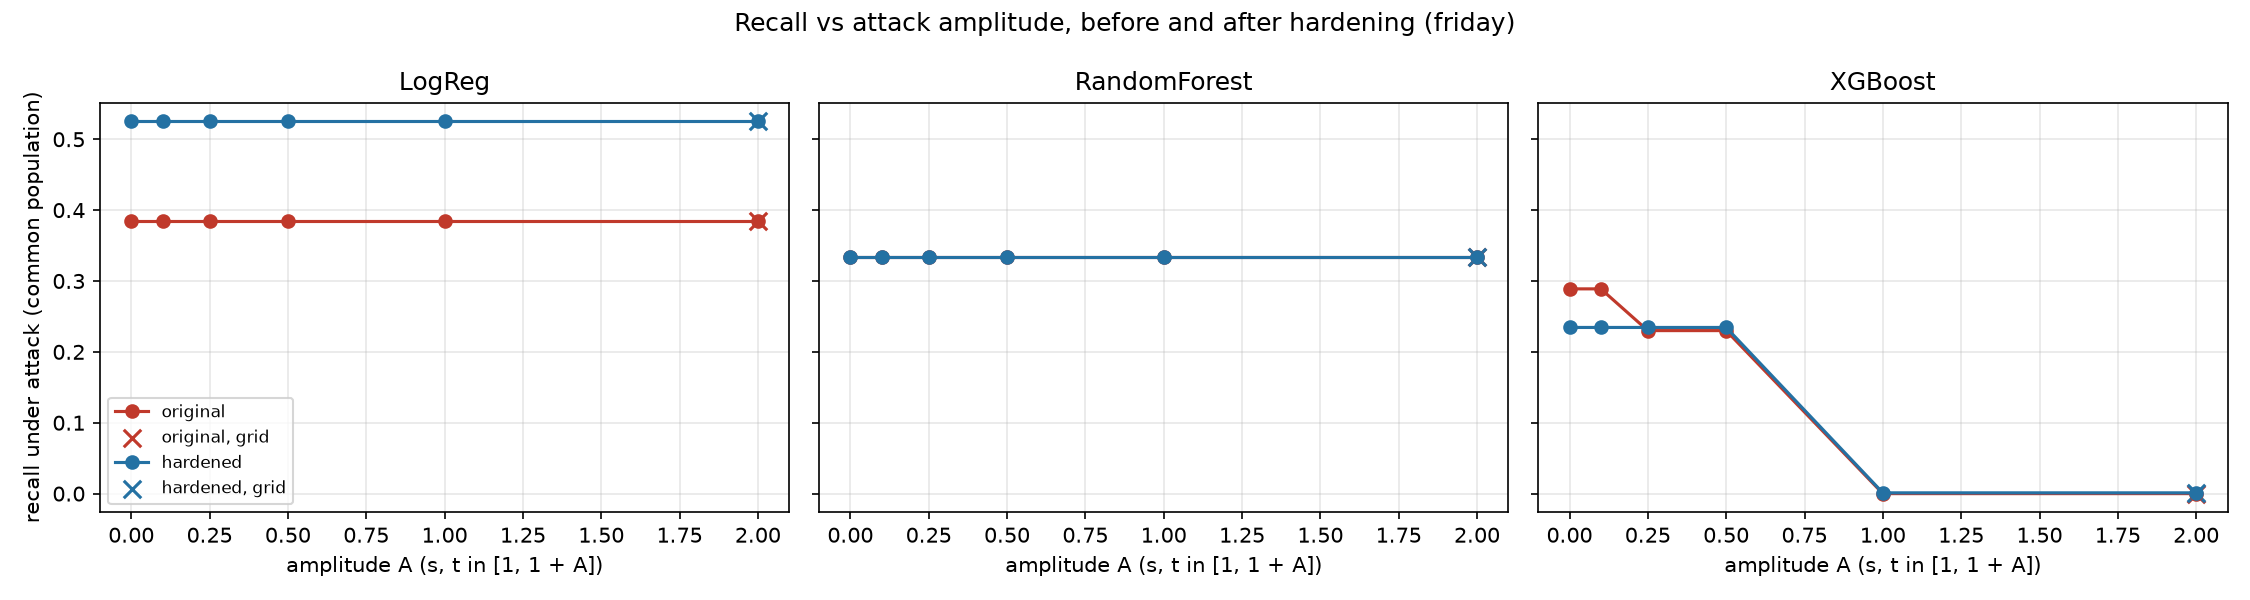

In [12]:
FRIDAY = RESULTS / "friday_clean.csv"
if FRIDAY.exists():
    display(pd.read_csv(FRIDAY).round(4))
    fri = pd.read_csv(RESULTS / "friday_per_family_clean.csv")
    display(fri.pivot_table(index=["family", "n"], columns=["detector", "state"], values="recall").round(4))
    fpool = pd.read_csv(RESULTS / "friday_recall_common_pooled.csv")
    display(fpool.pivot_table(index=["detector", "state"], columns="attack", values="recall").round(4))
    display(Image(filename=str(RESULTS / "friday_recall_vs_amplitude.png")))
else:
    print("Vendredi non évalué.")

## 10. Analyse critique

**Observé (test, exécution unique).** Les six modèles reconstruits reproduisent exactement les FP/FN de la validation : le test a bien été évalué avec les modèles gelés.

1. **Performance propre.** Sur 226 157 flux (15,00 % d'attaques), XGBoost est le meilleur (F1 0,9957, PR-AUC 0,99995, 4 FP et 287 FN), devant la forêt (F1 0,9923) et la régression logistique (F1 0,9867, 275 FP). Ces scores très élevés sont une **borne optimiste** : le découpage par strate met les mêmes familles d'attaque en train et en test, et il a été choisi après l'échec sur le jeudi. Les moyennes cachent des familles mal détectées : DoS Slowhttptest (rappel 0,33 à 0,87 selon le modèle) et DoS Slowloris (0,61 à 0,82).
2. **Coût FP / FN.** Pour un centre opérationnel, 275 fausses alertes (régression logistique) contre 3 ou 4 (forêt, XGBoost) sur environ 192 000 flux normaux représentent une différence réelle de charge d'analyste. Les FN sont concentrés sur les attaques lentes (Slowloris, Slowhttptest), qui ressemblent à du trafic normal peu actif : ce sont les attaques non détectées les plus coûteuses ici.
3. **Évasion sans durcissement.** La régression logistique est très fragile : rappel sous attaque sur la population commune de 0,818 à 0,519 (aléatoire, A = 2) et 0,490 (grille) ; SSH-Patator est évadé à 100 % dès A = 0,5. La forêt résiste aux petites amplitudes mais tombe de 0,836 à 0,675 à A = 2 (SSH-Patator évadé à 99 %).
4. **XGBoost n'est pas robuste sur le test.** Sur la validation, il n'avait que 2 évasions sur 1 800 flux. Sur le test, DoS Slowhttptest est évadé à 35 % (A = 0,5 à 1) et Slowloris à 9 % (A = 2) : rappel commun de 0,919 à 0,862. La quasi-insensibilité observée sur la validation **ne se généralisait pas** : c'est exactement pourquoi le test n'est utilisé qu'à la fin.
5. **Durcissement.** Après entraînement adverse, le rappel sous la pire attaque testée passe de 0,490 à 0,813 (régression logistique), de 0,675 à 0,844 (forêt) et de 0,862 à 0,926 (XGBoost), quasiment au niveau du rappel propre. 36 des 48 combinaisons avec évasion sont « améliorées » (intervalles de Wilson séparés), 12 non séparées, aucune « pire ». La performance propre ne baisse pas (elle augmente légèrement).
6. **Coût du durcissement.** La régression logistique durcie signale 2,5 % des flux normaux perturbés à A = 2 (0,52 % pour l'originale) : elle a en partie appris « flux perturbé = attaque » (**hypothèse**). La forêt et XGBoost durcis n'ont pas ce défaut (au plus 0,012 %).

7. **Vendredi, hors distribution (exécution unique séparée).** 547 557 flux, 46,6 % d'attaques, avec Portscan, DDoS et Botnet, familles absentes du train. Le rappel global s'effondre (0,27 à 0,69) alors que la précision reste ≥ 0,99 : Portscan est presque invisible pour la forêt et XGBoost (rappel 0,0005) et Botnet pour tous (≤ 0,045). DDoS reste détecté (0,71 à 0,999), probablement parce qu'il ressemble aux DoS vus en train (**hypothèse**). Sous attaque, XGBoost perd presque tout DDoS dès A = 1 (évasion 100 %, et encore 98,7 % une fois durci) : un durcissement appris sur les familles connues **ne se transfère pas** à une famille inconnue. Seule surprise positive, la régression logistique durcie passe de 0,45 à 0,69 de rappel propre (Portscan de 0,12 à 0,51), sans explication établie.

**Lecture du rappel « none ».** Sur la population commune (au plus 300 flux par famille), le rappel propre (0,82 à 0,93) est plus bas que le rappel global (0,98 à 0,99), car chaque famille pèse autant : les familles faibles (Slowhttptest, Slowloris, Heartbleed) comptent davantage. Heartbleed (2 flux) est rapporté mais non interprété.

## 11. Limites

- **Attaquant connu** : le durcissement est évalué contre la même famille de perturbations (`s`, `t` côté `Fwd`), avec une autre graine, une grille et une amplitude plus forte, mais **pas** contre un attaquant adaptatif qui connaîtrait la défense. Ce n'est pas une preuve de robustesse.
- **Modèle de menace restreint** : seules deux perturbations ; ajout de paquets, variables `Bwd` et vraie reconstruction de paquets non testés. Une modification de ligne CSV n'est pas une modification de trafic réel.
- **Borne optimiste** : découpage par strate choisi post hoc ; mêmes familles en train et en test ; le jeudi montre que des familles inconnues ne sont presque pas détectées.
- **Une seule graine d'entraînement**, pas d'intervalle sur les métriques propres ; temps mesurés une seule fois (bruités).
- **Provenance** : la spécification d'attaque v1 a été enregistrée rétroactivement ; l'attaque de la régression logistique et de la forêt, le durcissement des trois modèles et le contrôle BENIGN sur la validation sont post hoc (déclarés dans `docs/PROJECT_HANDOFF.md`). Le contrôle BENIGN sur le test était, lui, déclaré d'avance.
- Projet réalisé seul : les rôles défenseur et attaquant ont été joués successivement par la même personne.

## 12. Conclusion

Sur CIC-IDS2017 « improved », avec un découpage temporel par strate, les trois détecteurs atteignent des scores propres très élevés (F1 de 0,987 à 0,996 sur le test), mais **tous sont évadables** par un attaquant boîte noire réaliste qui ne fait que remplir ses paquets et retarder son trafic : la régression logistique perd jusqu'à 33 points de rappel, la forêt 16 points, et même XGBoost, qui semblait robuste sur la validation, perd des attaques lentes sur le test. L'entraînement adverse ramène le rappel sous attaque presque au niveau propre, sans coût sur la performance normale pour la forêt et XGBoost, avec un coût en fausses alertes pour la régression logistique. Le vendredi le confirme : face à des familles jamais vues, le rappel tombe sous 0,7 et le durcissement ne protège plus. Ce durcissement n'est donc démontré que contre l'attaque connue : la prochaine étape serait un attaquant adaptatif et d'autres perturbations.